# QA_max_cut_lib · руководство текущего CPU API

Версия **0.1.0a1**. Этот ноутбук охватывает реализованный функционал первого этапа. Полный целевой набор возможностей содержится в согласованной архитектуре и статусе переноса. Мы используем только фактически работающие методы.

План: графы → точный ориентир → схема и критерии QAOA → бюджет → результаты и сохранение → визуализация → карты. Для воспроизводимости seeds фиксированы. Для экспорта каждый полный проход ноутбука создаёт новое явно указанное имя папки.

Установите `python -m pip install -e ".[cpu,notebooks]"` из корня проекта и выберите его Python-ядро. Все ячейки рассчитаны на последовательное выполнение без NVIDIA и без системного TeX.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from copy import deepcopy
import json
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
from QA_max_cut_lib import WeightedGraph, GraphFactory, SolverFactory, ExactCPU, QAOACPU
from QA_max_cut_lib.generators import partition
from QA_max_cut_lib import tools
from QA_max_cut_lib.solvers.objectives import validate_objective, objective_value

root = Path.cwd() if (Path.cwd() / 'configs').is_dir() else Path.cwd().parent
export_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
output_dir = root / 'notebooks' / '_outputs' / ('guide_' + export_id)
style = {'text_engine': 'mathtext', 'figsize': [10, 6]}
print('Available solvers:', SolverFactory.available())

No event loop hook running.
Available solvers: ('exact_cpu', 'qaoa_cpu')


## 1. Задача и исходные номера

$$C(s)=\sum_{(i,j)\in E}w_{ij}(1-s_i s_j)/2,\qquad E(s)=-C(s).$$

Постоянная часть энергии не отброшена. Вершины имеют целочисленные метки с любыми пропусками, включая отрицательные. Изолированная вершина тоже должна получить спин. Нулевое ребро хранится в структуре, отрицательное сохраняет знак в функции качества.

Node order: (10, 30, 80, -7, 101)
Weighted edges: ((10, 30, 1.5), (30, 80, -0.5), (10, 80, 2.0), (-7, 80, 0.75))
Manual C: 4.25 E: -4.25


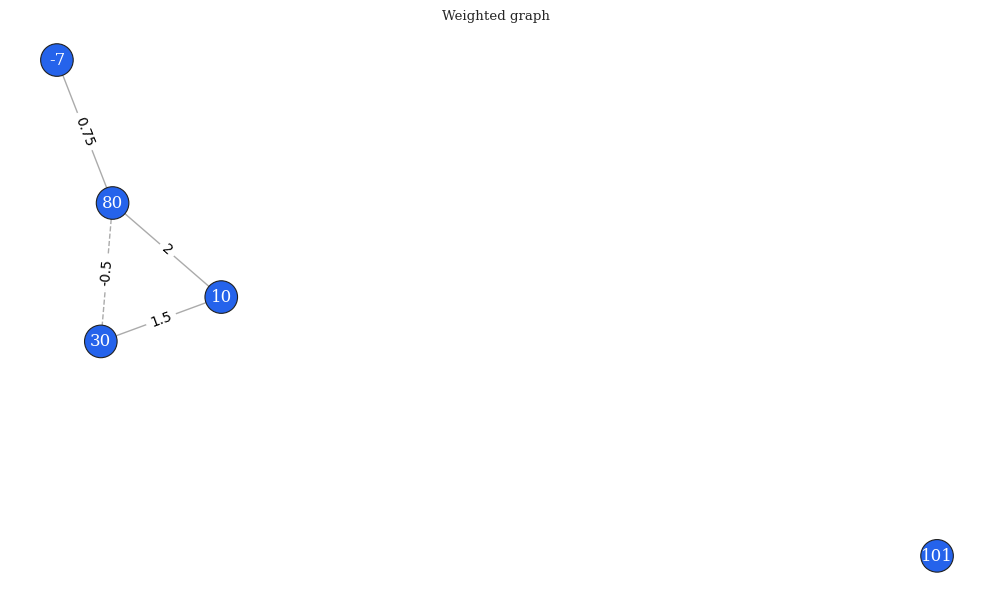

In [2]:
graph = WeightedGraph(
    [(10, 30, 1.5), (30, 80, -0.5), (10, 80, 2.0), (80, -7, 0.75)],
    nodes=[10, 30, 80, -7, 101],
)
print('Node order:', graph.nodes)
print('Weighted edges:', graph.edges)
manual = {10: 1, 30: -1, 80: -1, -7: 1, 101: 1}
print('Manual C:', graph.cut_value(manual), 'E:', -graph.cut_value(manual))
figure = tools.plot_graph(graph, {'style': style})
display(figure)
plt.close(figure)

## 2. Изменения графа, подграфы и разбиение

Редактирование выполняется на существующем объекте. `subgraph` создаёт индуцированный подграф без изменения внешних номеров. `partition` случайно разбивает вершины; межчастные рёбра не включены в подграфы, поэтому сумма решений частей сама по себе не решает исходную задачу.

In [3]:
editable = graph.copy()
before = editable.snapshot()['fingerprint']
editable.set_weight(10, 30, 2.25)
editable.add_node(500)
editable.set_weight(101, 500, 0.0)
editable.remove_edge(101, 500)
assert editable.snapshot()['fingerprint'] != before
small = editable.subgraph([80, 10, 101])
parts = partition(editable, 2, seed=3)
print('Subgraph:', small.nodes, small.edges)
print('Partition:', [part.nodes for part in parts])
snapshot = editable.snapshot()
assert WeightedGraph.from_snapshot(snapshot).snapshot() == snapshot

Subgraph: (80, 10, 101) ((10, 80, 2.0),)
Partition: [(80, 500), (101, 30), (-7, 10)]


## 3. Все реализованные рецепты

Топология: Complete, G(n,m), Erdős–Rényi G(n,p). Веса: константа, равновероятный список или равномерный интервал. В рецепте и снимке сохраняются отдельные seeds. Поддержка графа на 1000 вершин относится к представлению и генерации; прямой полный QAOA имеет экспоненциальный размер состояния и малый защитный предел.

In [4]:
recipes = [
    {'type': 'complete', 'seed': 7, 'parameters': {'n_vertices': 5},
     'weights': {'type': 'constant', 'parameters': {'value': 1.0}, 'seed': 8}},
    {'type': 'gnm', 'seed': 7, 'parameters': {'n_vertices': 5, 'n_edges': 4},
     'weights': {'type': 'signed_discrete', 'parameters': {'values': [-1., 1.]}, 'seed': 8}},
    {'type': 'erdos_renyi', 'seed': 7, 'parameters': {'n_vertices': 5, 'probability': .4},
     'weights': {'type': 'uniform', 'parameters': {'low': -1., 'high': 2.}, 'seed': 8}},
]
for recipe in recipes:
    generated = GraphFactory.from_recipe(recipe)
    repeated = GraphFactory.from_recipe(recipe)
    assert generated.snapshot() == repeated.snapshot()
    print(recipe['type'], len(generated), 'nodes;', len(generated.edges), 'edges')

complete 5 nodes; 10 edges
gnm 5 nodes; 4 edges
erdos_renyi 5 nodes; 3 edges


## 4. ExactCPU и нормированное качество

Перебор фиксирует первый спин в +1 благодаря глобальной инверсии, затем восстанавливает полное число вырожденных максимумов. Два прохода позволяют не хранить все стоимости: сначала экстремумы, затем точный подсчёт относительно найденного максимума. Это полный перебор в float64, а не символьная арифметика.

`quality_score=(C−C_min)/(C_max−C_min)` уместен для знаковых весов, когда известны оба экстремума **этого же графа**. При нулевом диапазоне возвращается None.

In [5]:
reference = ExactCPU({'parameters': {'batch_size': 16}, 'output': {'color': 'never'}})
reference.solve(graph, report=1, logs=0, num_treads=1)
print('C_max:', reference.cut_value, 'C_min:', reference.worst_cut_value)
print('Optimal assignments:', reference.optimal_count)
print('Evaluations in two passes:', reference.states_evaluated)
print('Manual solution quality:', tools.quality_score(
    graph.cut_value(manual), reference.cut_value, reference.worst_cut_value))

QA_max_cut_lib | exact_cpu | completed
Cut: 4.25   Energy: -4.25   Time: 0.0007 s
Resources: {"num_stages": 2, "num_treads": 1, "shots_used": 0, "states_evaluated": 32}
C_max: 4.25 C_min: 0.0
Optimal assignments: 4
Evaluations in two passes: 32
Manual solution quality: 1.0


## 5. Схема QAOA и знак энергии

Начальное состояние $|+\rangle^N$. В каждом слое сначала действует $\exp(-i\gamma H_E)=\exp(+i\gamma C)$, затем $\exp(-i\beta\sum_iX_i)$. Порядок углов: все $\gamma$, затем все $\beta$.

Для единственного ребра w=1 получаем $\langle C\rangle=[1-\sin\gamma\sin(4\beta)]/2$. Проверим аналитическую точку: $\gamma=-\pi/2$, $\beta=\pi/8$. Сбор состояния включён явно; нулевая длина обучения означает readout исходных углов.

In [6]:
edge = WeightedGraph([(7, 20, 1.0)])
analytic = QAOACPU({
    'seed': 1,
    'optimizer': {'parameters': {'max_steps': 0}},
    'initialization': {'type': 'fixed_angles', 'parameters': {'values': [-np.pi/2, np.pi/8]}},
    'collect': {'probabilities': True, 'statevector': True, 'correlations': True},
})
analytic.solve(edge)
assert np.isclose(analytic.expected_energy, -1.0)
assert np.isclose(np.vdot(analytic.statevector, analytic.statevector), 1.0)
assert np.isclose(analytic.correlations[0, 1], -1.0)
assert analytic.objective_value is None
print('Expected E:', analytic.expected_energy)
print('Probabilities:', analytic.probabilities)
print('Physical correlations:', analytic.correlations)

Expected E: -1.0
Probabilities: [3.55016284e-33 5.00000000e-01 5.00000000e-01 3.55016284e-33]
Physical correlations: [[ 1. -1.]
 [-1.  1.]]


## 6. Пять критериев: F максимизируется, L=−F минимизируется

Mean Cut даёт $L=\langle E\rangle$. CVaR усредняет лучшие α долей вероятностной массы с дроблением граничного состояния. Gibbs — $\log\langle e^{\eta C}\rangle/\eta$. Best-of-K — ожидание лучшего из K независимых значений C. Threshold Probability — $P(C\ge A)=P(E\le-A)$.

У последних четырёх `optimizer_loss` нельзя автоматически называть обычной средней физической энергией. Пороговая вероятность безразмерна. Проверим критерии сначала на одной известной распределённой случайной величине, затем выполним независимые QAOA-запуски.

In [7]:
objectives = [
    {'type': 'mean_cut', 'parameters': {}},
    {'type': 'cvar', 'parameters': {'alpha': .5}},
    {'type': 'gibbs', 'parameters': {'eta': .7}},
    {'type': 'best_of_k', 'parameters': {'k': 3}},
    {'type': 'threshold_probability', 'parameters': {'threshold': 2.5}},
]
cuts = np.array([-2., 0., 3.])
masses = np.array([.2, .3, .5])
for objective in objectives:
    resolved = validate_objective(objective)
    print(objective['type'], 'F =', round(objective_value(cuts, masses, resolved), 6))

criterion_runs = []
for objective in objectives:
    solver = QAOACPU({'seed': 4, 'objective': objective,
                     'optimizer': {'parameters': {'max_steps': 8}},
                     'readout': {'mode': 'best_of_shots', 'shots': 64}})
    solver.solve(graph)
    criterion_runs.append(solver.last_run)
    print(objective['type'], 'L =', round(solver.optimizer_loss, 6),
          'solution E =', solver.solution_energy)

mean_cut F = 1.1
cvar F = 3.0
gibbs F = 2.12706
best_of_k F = 2.609
threshold_probability F = 0.5
mean_cut L = -2.008015 solution E = -4.25
cvar L = -3.196381 solution E = -4.25
gibbs L = -2.710943 solution E = -4.25
best_of_k L = -3.250886 solution E = -4.25
threshold_probability L = -0.289445 solution E = -4.25


## 7. Многослойная оптимизация и накопление

ADAM получает центральные разности функции потерь. На p слоях d=2p параметров; один полный шаг требует 2d+1 оценок. История шагов содержит центры, подробная история — также градиентные пробы. Для конечного решения выбираются лучшие уже оценённые углы, поэтому `optimal_angles` могут принадлежать пробе, а не центру шага.

Здесь используем p=2 и complex64. Небольшие различия относительно complex128 — ожидаемая численная погрешность. Все большие выходы включаются отдельно через collect.

Angles [gamma0, gamma1, beta0, beta1]: [ 2.46099336 -1.83819702  0.03578953 -0.48066864]
State dtype: complex64
History rows: 20 180


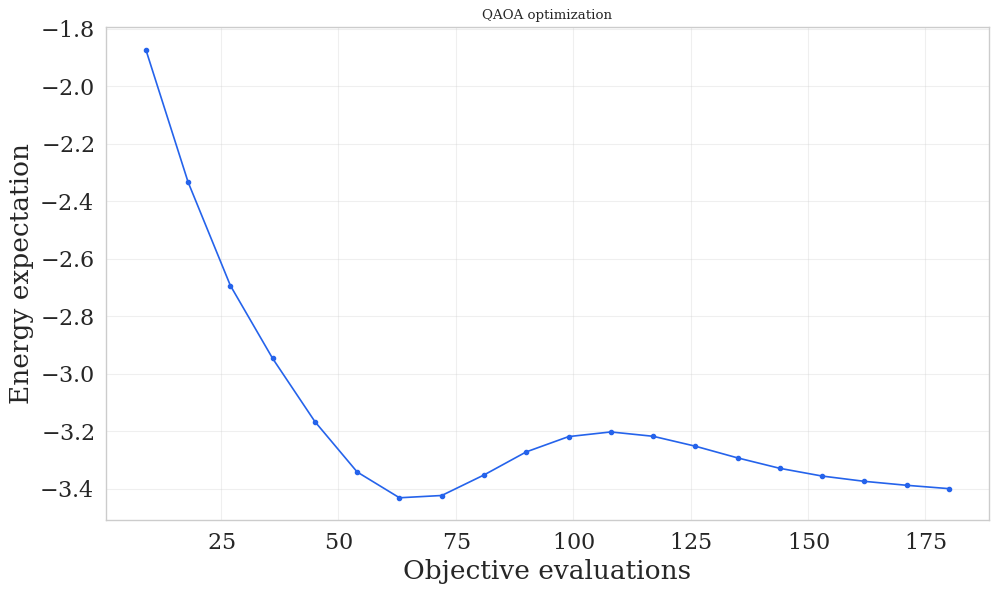

In [8]:
training_config = {
    'type': 'qaoa_cpu', 'seed': 17, 'num_treads': 1,
    'parameters': {'layers': 2, 'dtype': 'complex64'},
    'initialization': {'type': 'random_angles'},
    'optimizer': {'parameters': {'max_steps': 20, 'learning_rate': .05},
                  'gradient': {'type': 'central_difference', 'parameters': {'step': .02}}},
    'collect': {'optimizer_history': True, 'objective_history': True,
                'probabilities': True, 'statevector': True, 'correlations': True},
    'readout': {'mode': 'best_of_shots', 'shots': 128},
    'output': {'report': 0, 'logs': 0, 'color': 'never'},
}
algorithm = SolverFactory.from_config(training_config)
algorithm.solve(graph)
print('Angles [gamma0, gamma1, beta0, beta1]:', algorithm.optimal_angles)
print('State dtype:', algorithm.statevector.dtype)
print('History rows:', len(algorithm.optimizer_history), len(algorithm.objective_history))
assert algorithm.resources['objective_evaluations'] == 20 * 9
np.testing.assert_allclose(tools.correlation_matrix(algorithm.probabilities), algorithm.correlations)
figure = tools.plot_optimization(algorithm, {'style': style, 'axes': {'x': 'objective_evaluations'}})
display(figure)
plt.close(figure)

## 8. Шотовая оценка и строгий общий бюджет

При шотовом обучении каждая проба использует отдельную выборку. Это особенно шумно при малом шаге разности; для нелинейных критериев подстановочная оценка может быть смещена. Конечный readout — отдельный расход.

Пример p=1: полный шаг = 5 оценок ×16 шотов =80. Readout требует 32. Бюджет 120 допускает один шаг и readout, всего 112; второй шаг начинать нельзя. `expected_energy` всё равно вычисляется точно по конечному симулированному состоянию и явно отличается от шотовой тренировочной оценки.

In [9]:
sampled = QAOACPU({
    'seed': 6, 'estimation': {'mode': 'shots', 'shots_per_evaluation': 16},
    'optimizer': {'parameters': {'max_steps': 5},
                  'gradient': {'type': 'central_difference', 'parameters': {'step': .1}}},
    'readout': {'mode': 'best_of_shots', 'shots': 32},
    'limits': {'shots_total': 120},
    'collect': {'optimizer_history': True},
    'output': {'color': 'never'},
})
sampled.solve(graph, report=1, logs=1)
assert sampled.status == 'stopped'
assert sampled.resources['shots_used'] == 112
assert sampled.resources['optimizer_steps'] == 1
print('Training objective:', sampled.objective_value, sampled.objective_source)
print('Exact final expected E:', sampled.expected_energy, sampled.expected_cut_source)

readout_only = QAOACPU({
    'seed': 6, 'estimation': {'mode': 'shots', 'shots_per_evaluation': 16},
    'readout': {'mode': 'best_of_shots', 'shots': 32}, 'limits': {'shots_total': 32},
})
readout_only.solve(graph)
assert readout_only.objective_value is None
assert readout_only.resources['shots_used'] == 32
print('Budget reserved only for readout:', readout_only.termination_reason)

QAOA training starts.
QAOA stops: shot_budget; total shots=112.
QA_max_cut_lib | qaoa_cpu | stopped
Cut: 4.25   Energy: -4.25   Time: 0.0019 s
Resources: {"num_stages": 2, "num_treads": 1, "objective_evaluations": 5, "optimizer_steps": 1, "readout_shots": 32, "shots_used": 112, "training_shots": 80}
Training objective: 1.046875 best_training_evaluation
Exact final expected E: -0.9203547672049286 exact_final_statevector
Budget reserved only for readout: shot_budget


## 9. Результат, история и изменяемый вход

`result` — полный JSON-совместимый снимок. Нативный `last_run` не меняется после нового solve. Научные массивы возвращаются копиями; изменение полученного массива не изменяет запись. В солвере хранится только последний запуск, историю собираем отдельно.

In [10]:
first_record = algorithm.last_run
history = [first_record]
first_solution = first_record.solution
first_fingerprint = first_record.graph['fingerprint']
copy_of_probabilities = first_record.probabilities
copy_of_probabilities[:] = 0
assert np.isclose(first_record.probabilities.sum(), 1)
repeat_solution = algorithm.solve(graph)
history.append(algorithm.last_run)
assert repeat_solution == first_solution

changed_graph = graph.copy()
changed_graph.set_weight(10, 30, 4.0)
algorithm.solve(changed_graph)
history.append(algorithm.last_run)
assert first_record.graph['fingerprint'] == first_fingerprint
assert algorithm.graph['fingerprint'] != first_fingerprint
full_json = first_record.result
json.dumps(full_json, allow_nan=False)
print('Collected runs:', len(history))
print('JSON state encoding:', full_json['statevector']['__type__'], full_json['statevector']['dtype'])

Collected runs: 3
JSON state encoding: ndarray <c8


## 10. JSON, NPY и автоматическое save

`atts` и `save_original_data` независимы. Если массив входит только во второй список, его содержимое не дублируется в JSON. Ссылки относительные; для переноса перемещайте весь комплект. Комплексное состояние сохраняет свой dtype. При `atts=[]` остаются обязательные метаданные и отчёт.

In [11]:
export_config = {
    'path': str(output_dir), 'filename': 'two_layer_run',
    'atts': ['solution', 'solution_energy', 'expected_energy', 'optimal_angles',
             'optimizer_history', 'objective_history', 'correlations'],
    'save_original_data': ['statevector', 'probabilities'],
    'makedir': True, 'savedir': True,
}
saved = tools.save_result(first_record, export_config)
loaded = tools.load_result(saved.primary, load_original_data=True)
np.testing.assert_array_equal(loaded.statevector, first_record.statevector)
assert loaded.statevector.dtype == np.complex64
assert loaded.solution == first_solution
print('Export:', [path.name for path in saved.files])

auto = ExactCPU({'save': {
    'path': str(output_dir), 'filename': 'automatic_exact',
    'atts': ['solution', 'solution_energy', 'optimal_count'],
    'makedir': True, 'savedir': False,
}})
auto.solve(graph, report=0, logs=0)
assert (output_dir / 'automatic_exact.json').is_file()
print('Automatic export works with report=0 and logs=0.')

Export: ['two_layer_run_statevector.npy', 'two_layer_run_probabilities.npy', 'two_layer_run.json']
Automatic export works with report=0 and logs=0.


## 11. Единое оформление и экспорт графиков

Простой граф, граф с решением и граф со статистикой используют один стиль. Передача солвера берёт снимок именно его запуска. Ниже входом служит загруженная запись первого запуска, а не последний изменённый граф.

Форматы текущего этапа: PNG, JPEG, PDF, SVG. `DPI` влияет на растровый экспорт. `metadata=True` добавляет видимую подпись. Самостоятельные метаданные инструмента доступны через `figure.qa_record.result`; `atts` включает также отдельный JSON инструмента.

Tool result fields: ('schema_version', 'algorithm_type', 'package_version', 'status', 'finished_at', 'config', 'source', 'graph', 'plot_data')
Plot export: ['probability_plot.pdf', 'probability_plot.json']


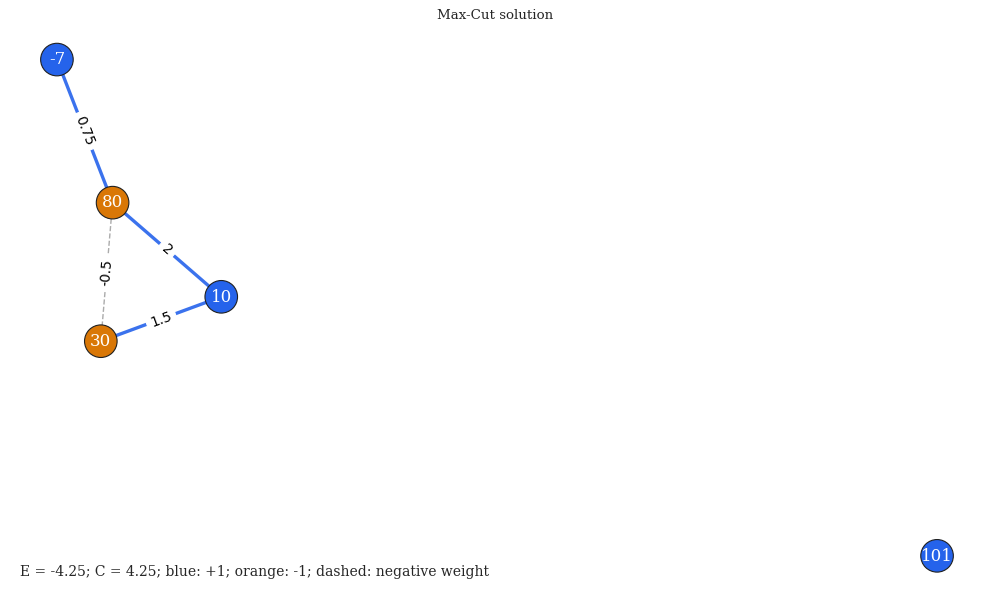

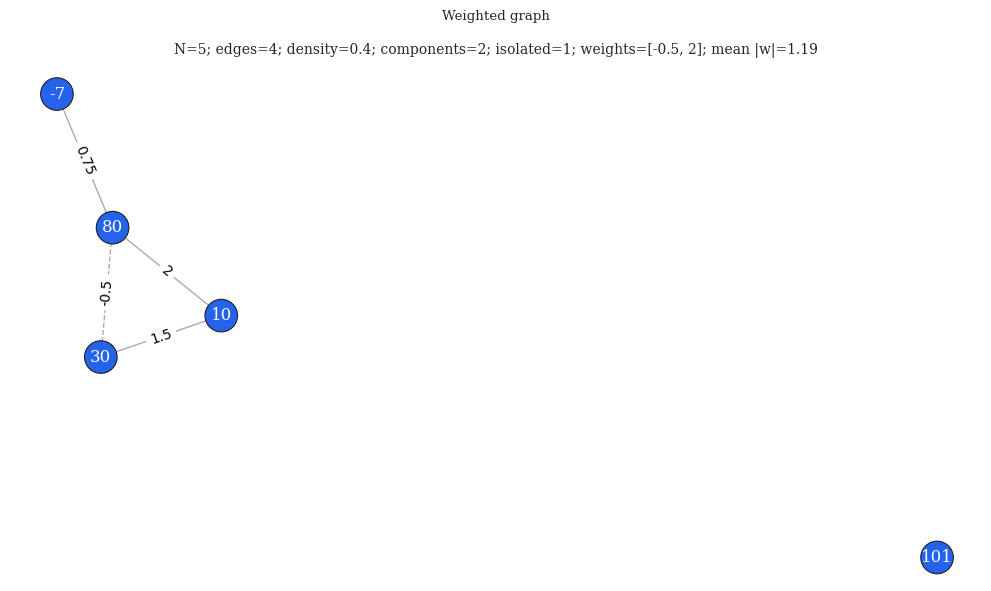

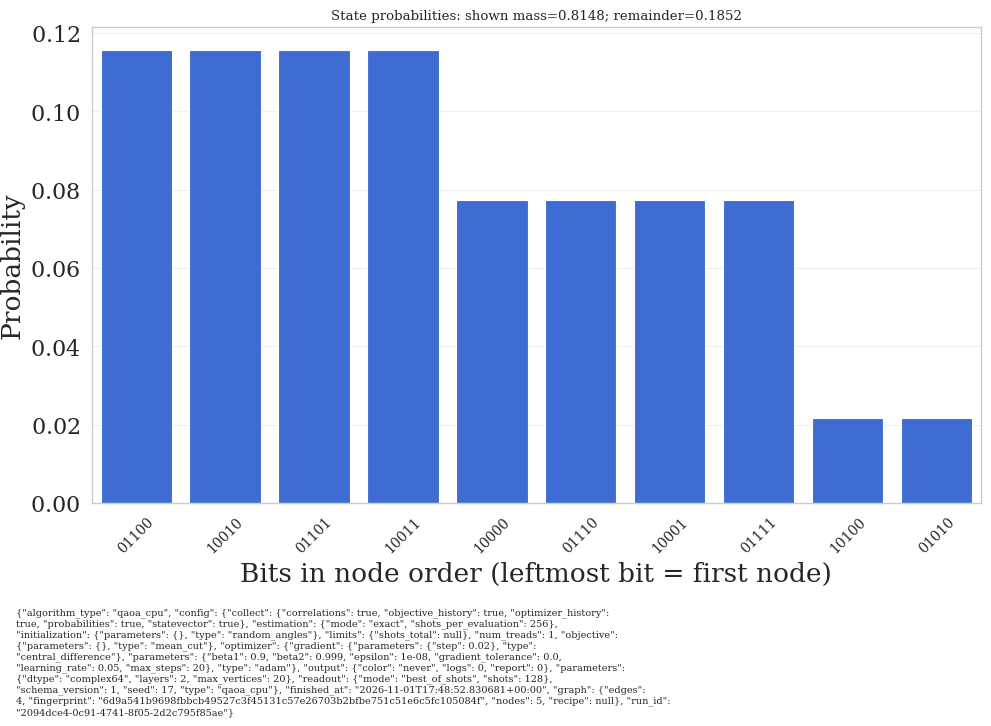

In [12]:
figure = tools.plot_graph_solution(loaded, config={'style': style})
display(figure)
plt.close(figure)
figure = tools.plot_graph_info(loaded, {'style': style})
display(figure)
plt.close(figure)

figure = tools.plot_probabilities(loaded, {
    'style': style, 'selection': {'top_k': 10},
    'save': {'path': str(output_dir), 'filename': 'probability_plot', 'format': 'pdf',
             'DPI': 250, 'metadata': True, 'atts': ['source', 'plot_data'],
             'makedir': True, 'savedir': True},
})
display(figure)
print('Tool result fields:', figure.qa_record.field_names)
print('Plot export:', [path.name for path in figure.qa_saved_files.files])
plt.close(figure)

## 12. Карта ландшафта p=1

Сканер вычисляет карту без оптимизации, по явной сетке γ и β. По умолчанию цвет обозначает `optimizer_loss`, для Mean Cut это $\langle E\rangle$. Строка массива — β, столбец — γ. Окно γ выбирается исследователем: при произвольных действительных весах универсальный период не предполагается.

Сохраним карту как исходный массив, чтобы в дальнейшем менять оформление без нового расчёта. Интерактивный трёхмерный HTML пока находится в плане переноса.

Grid points: 625
Minimum grid energy expectation: -3.339861928248701


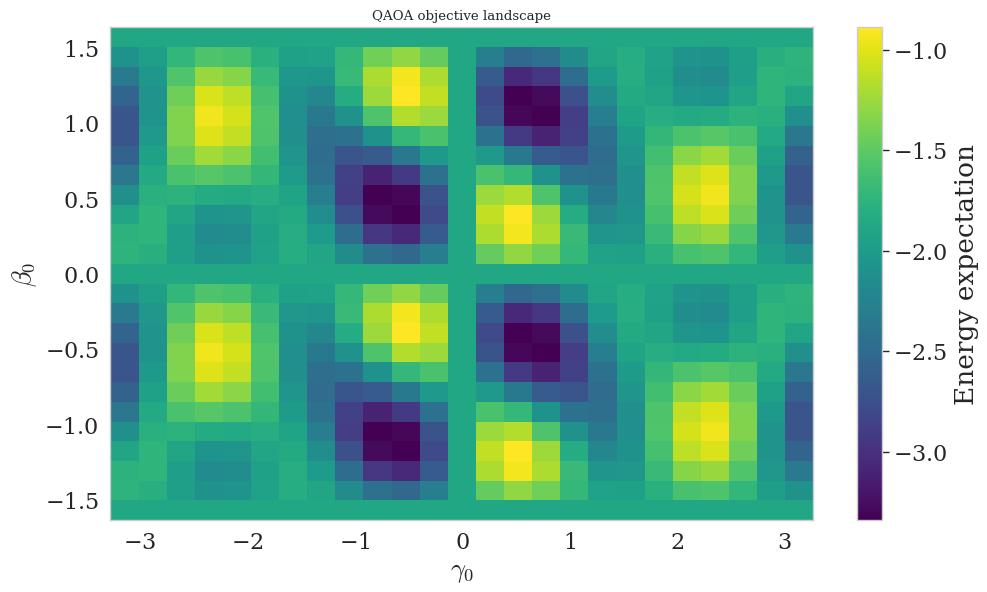

In [13]:
landscape = tools.scan_landscape(graph, {
    'gamma': np.linspace(-np.pi, np.pi, 25).tolist(),
    'beta': np.linspace(-np.pi/2, np.pi/2, 25).tolist(),
    'objective': {'type': 'mean_cut', 'parameters': {}},
    'quantity': 'optimizer_loss',
    'save': {'path': str(output_dir), 'filename': 'energy_map',
             'atts': ['gamma', 'beta'], 'save_original_data': ['values'],
             'makedir': True, 'savedir': True},
})
assert landscape.values.shape == (25, 25)
map_files = output_dir / 'energy_map' / 'energy_map.json'
loaded_map = tools.load_result(map_files, load_original_data=True)
np.testing.assert_array_equal(loaded_map.values, landscape.values)
figure = tools.plot_landscape(loaded_map, {
    'style': style,
    'save': {'path': str(output_dir), 'filename': 'energy_landscape', 'format': 'png',
             'DPI': 250, 'metadata': False, 'makedir': True},
})
display(figure)
plt.close(figure)
print('Grid points:', landscape.resources['grid_points'])
print('Minimum grid energy expectation:', float(landscape.values.min()))

## 13. Явные ошибки и границы этапа

Несобранная история или вероятность не вычисляется повторно по просьбе графика. Существующие файлы защищены. `num_treads>1`, GPU-типы и checkpoint/resume пока отклоняются. Это позволяет отличить работающий режим от ещё не перенесённого.

In [14]:
try:
    tools.save_result(first_record, export_config)
except FileExistsError:
    print('Expected: existing files are protected.')
else:
    raise AssertionError('The export must be exclusive.')

for name, action in [
    ('Parallel CPU', lambda: ExactCPU().solve(graph, num_treads=2)),
    ('Checkpoint', lambda: QAOACPU({'checkpoint': {'enabled': True}})),
    ('GPU type', lambda: SolverFactory.from_config({'type': 'qaoa_gpu'})),
    ('Missing probabilities', lambda: tools.plot_probabilities(reference)),
]:
    try:
        action()
    except ValueError as error:
        print(name + ':', error)
    else:
        raise AssertionError(name + ' must be rejected in this milestone.')

Expected: existing files are protected.
Parallel CPU: Parallel CPU execution is not implemented in this milestone; use num_treads=1.
Checkpoint: Checkpoint/resume is planned, not implemented in milestone 0.1.0a1.
GPU type: Solver 'qaoa_gpu' is not implemented in 0.1.0a1. Available: ('exact_cpu', 'qaoa_cpu')
Missing probabilities: No probabilities were collected. Enable collect.probabilities before solve().


## 14. Запуск из модуля и справочник

```bash
python -m QA_max_cut_lib.solvers.exact_cpu --report 1 --logs 0
python -m QA_max_cut_lib.solvers.qaoa_cpu --graph configs/graphs/complete_signed_7.json --config configs/solvers/qaoa_cpu.json --report 2 --logs 1
```

Уровни отчёта и логов независимы: 0 — выключено, 1 — кратко, 2 — подробно. Цвет настраивается `output.color=auto|always|never`.

Полная таблица аргументов и атрибутов находится в `docs/API.md`. Вывод формул, соглашения о знаке и различия оценок — в `docs/MATHEMATICS.md`. Для следующих этапов предусмотрены заменяемые компоненты LS/RQAOA, независимые CPU/GPU-алгоритмы, общий бенчмарк, профилировщик потоков, контрольные точки и траектории редукций; их состояние указано в `docs/MIGRATION_STATUS.md`.